# Experimento A/B en página de inicio

Este proyecto evalúa dos versiones de una landing page, A y B, mediante pruebas estadísticas y visualizaciones para fundamentar una decisión de negocio.

El archivo `landing_experiment.csv` contiene la región, el dispositivo, la fuente de tráfico, el tipo de usuario, la conversión y el gasto de los usuarios expuestos al experimento.

### Estructura del análisis
1. Exploración y validación de datos.
2. Comparación del gasto promedio de usuarios convertidos.
3. Comparación de tasas de conversión.
4. Asociación entre fuente de tráfico y conversión.
5. Asociación entre tipo de usuario y conversión.
6. Visualización de resultados.
7. Síntesis ejecutiva y recomendaciones.


## Lectura y reproducción

Los gráficos, tablas y resultados de la ejecución original están guardados en este notebook. Para recalcularlos, abre Jupyter desde la raíz del proyecto y coloca `landing_experiment.csv` en la carpeta `data/`. Las instrucciones de instalación están en el [README](README.md).


## 1. Carga y validación de datos

### 1.1 Carga y vista inicial


In [33]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [34]:
from pathlib import Path

data_dir = Path("data")
required_files = ['landing_experiment.csv']
missing = [name for name in required_files if not (data_dir / name).is_file()]
if missing:
    raise FileNotFoundError("Faltan archivos en data/: " + ", ".join(missing) + ". Consulta README.md.")

# cargar archivo
df = pd.read_csv(data_dir / 'landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [35]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [36]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB



 - No se observan valores nulon en ninguna columna

 - La columna date es de tipo de dato object y debería de ser una fecha

       

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


**Variable `user_id`**

Revisión de usuarios únicos.


In [37]:
df["user_id"].nunique()

40000

**Variable `date`**

Exploración del rango de fechas.


In [38]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [39]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [40]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [41]:
# Resumen estadístico de usuarios que se convirtieron
df["converted"].value_counts(normalize=True) * 100

0    85.735
1    14.265
Name: converted, dtype: float64

**Variables categóricas**

Revisión de las versiones A y B del experimento.


In [42]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print(df["landing"].value_counts(normalize=True) * 100)


Conteo de categorías:
B    50.045
A    49.955
Name: landing, dtype: float64


## 2. Comparación del gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [43]:
# Gasto por versión
gasto_A = df['gasto'][(df['landing'] == 'A') & (df['converted'] == 1)]
gasto_B = df['gasto'][(df['landing'] == 'B') & (df['converted'] == 1)]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [44]:
from scipy.stats import levene

estadistico, p_valor = levene(gasto_A, gasto_B)

print(f"Estadístico: {estadistico:.4f}")
print(f"Valor p: {p_valor:.4f}")

alpha = 0.05  # umbral de significancia
if p_valor < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia de varianzas diferentes (equal_var=True).")

Estadístico: 29.1765
Valor p: 0.0000
Rechazamos la hipótesis nula: hay evidencia de varianzas diferentes (equal_var=False).


### Prueba t

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los usuarios convertidos es el mismo en ambas páginas.
- **Hipótesis alternativa (H₁):** El gasto promedio de los usuarios convertidos es diferente entre las páginas A y B.

In [45]:
# Aplicar prueba
from scipy.stats import ttest_ind
estadistico, p_valor = ttest_ind(gasto_A, gasto_B,equal_var=False)


# Visualizar resultados
print(f"Estadístico t: {estadistico:.4f}")
print(f"Valor p: {p_valor:.7f}")

Estadístico t: -9.4810
Valor p: 0.0000000


### Conclusión e interpretación

Existe evidencia estadísticamente significativa de que el gasto promedio de los usuarios convertidos difiere entre las páginas A y B.


---

## 3. Comparación de la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.


### Prueba Z de proporciones

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión de la página A es igual a la de la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión de la página A es diferente de la de la página B.


In [46]:
# Número de usuarios convertidos por página
convertidos = df.groupby("landing")["converted"].sum()


# Total de usuarios por página
total_usuarios = df.groupby("landing")["converted"].count()


print("Usuarios convertidos por página:\n", convertidos)
print("\nTotal de usuarios por página:\n", total_usuarios)


Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [47]:
# Aplicar prueba
from statsmodels.stats.proportion import proportions_ztest

estadistico, p_valor = proportions_ztest(
    count=convertidos,
    nobs=total_usuarios
)

# Visualizar resultados
print(f"Estadístico Z: {estadistico:.4f}")
print(f"Valor p: {p_valor:.8f}")

Estadístico Z: -9.6774
Valor p: 0.00000000


### 📝 Conclusión e interpretación

**Decisión:**  
Existe evidencia estadísticamente significativa de que la tasa de conversión difiere entre la página A y la página B.

**Interpretación de negocio:**  
La página B muestra una tasa de conversión significativamente mayor que la página A, lo que sugiere que es la versión más efectiva para convertir usuarios en clientes.

## 4. Asociación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.


### Prueba chi-cuadrado

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico y la conversión son independientes; es decir, la tasa de conversión es la misma independientemente de la fuente de tráfico
- **Hipótesis alternativa (H₁):** La fuente de tráfico y la conversión no son independientes; es decir, existe una asociación entre la fuente de tráfico y la conversión


In [48]:
# Aplicar prueba
from scipy.stats import chi2_contingency

# Tabla de contingencia
tabla = pd.crosstab(df["traffic_source"], df["converted"])

# Aplicar prueba
chi2, p_valor, gl, esperados = chi2_contingency(tabla)
print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_valor:.4f}")
print(f"Grados de libertad: {gl}")

Estadístico Chi-cuadrado: 8.6621
Valor p: 0.0341
Grados de libertad: 3


### 📝 Conclusión e interpretación

**Decisión:**  
se rechaza la hipótesis nula. Existe evidencia estadísticamente significativa de que la fuente de tráfico y la conversión están asociadas.

**Interpretación de negocio:**  
Los resultados indican que la tasa de conversión varía según la fuente de tráfico, por lo que algunos canales son más efectivos para generar conversiones que otros


## 5. Asociación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.


### Prueba chi-cuadrado

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario y la conversión son independientes; es decir, la probabilidad de conversión es la misma para usuarios nuevos y recurrentes
- **Hipótesis alternativa (H₁):** El tipo de usuario y la conversión no son independientes; es decir, existe una asociación entre el tipo de usuario y la conversión


In [49]:
from scipy.stats import chi2_contingency


In [50]:
# Tabla de contingencia
tabla = pd.crosstab(df["user_type"], df["converted"])

# Aplicar prueba
chi2, p_valor, gl, esperados = chi2_contingency(tabla)

# Visualizar resultados
print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_valor:.4f}")
print(f"Grados de libertad: {gl}")


Estadístico Chi-cuadrado: 0.5135
Valor p: 0.4736
Grados de libertad: 1


### 📝 Conclusión e interpretación

**Decisión:**  
no se rechaza la hipótesis nula. No existe evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión.

**Interpretación de negocio:**  
Los resultados sugieren que, en los datos analizados, ser un usuario nuevo o recurrente no influye significativamente en la probabilidad de conversión.

## 6. Visualización de resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.


### Tasas de conversion y gasto promedio por Landing A/B

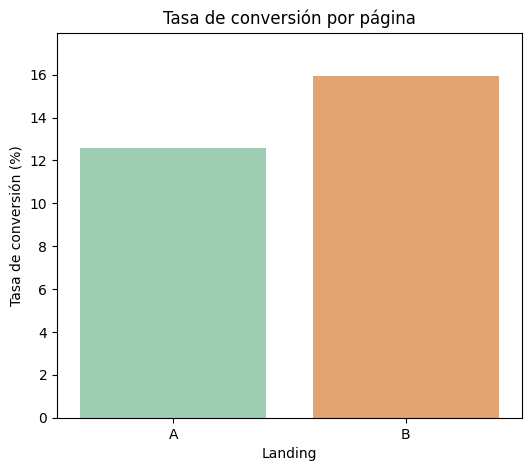

In [51]:
# Calcular tasa de conversión por landing
tasa_conversion = (
    df.groupby('landing')['converted']
      .mean()
      .mul(100)
      .round(2)
)

plt.figure(figsize=(6,5))
ax = sns.barplot(
    x=tasa_conversion.index,
    y=tasa_conversion.values,
    palette=["#95D5B2", "#F4A261"]
)
plt.title('Tasa de conversión por página')
plt.xlabel('Landing')
plt.ylabel('Tasa de conversión (%)')
plt.ylim(0, tasa_conversion.max()+2)
plt.show()

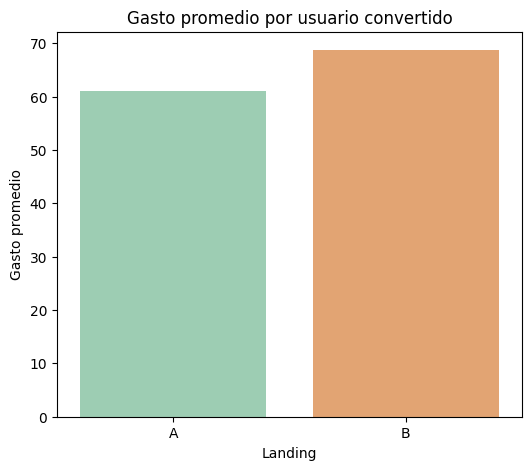

In [52]:
# Gasto promedio de usuarios convertidos
gasto_promedio = (
    df[df['converted']==1]
      .groupby('landing')['gasto']
      .mean()
      .round(2)
)

plt.figure(figsize=(6,5))
ax = sns.barplot(
    x=gasto_promedio.index,
    y=gasto_promedio.values,
    palette=["#95D5B2", "#F4A261"] )
plt.title('Gasto promedio por usuario convertido')
plt.xlabel('Landing')
plt.ylabel('Gasto promedio')
plt.show()

✍️ **Comentario**: 

Los gráficos muestran que la página B supera a la página A tanto en la tasa de conversión como en el gasto promedio por usuario convertido. Estos resultados coinciden con las pruebas estadísticas realizadas


### Relación entre la fuente de tráfico y la conversión

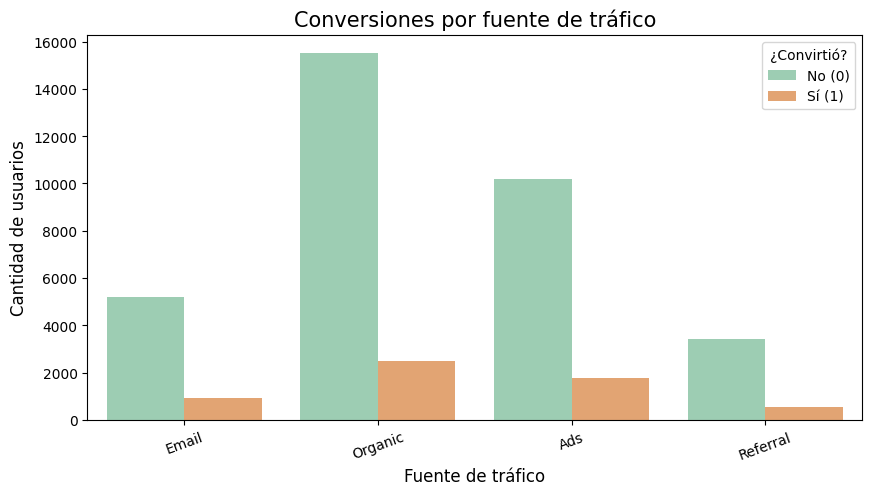

In [53]:
# Gráfico de barras agrupadas
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x='traffic_source',
    hue='converted',
    palette=["#95D5B2", "#F4A261"]
)

# Añadir detalles
plt.title('Conversiones por fuente de tráfico', fontsize=15)
plt.xlabel('Fuente de tráfico', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.xticks(rotation=20)
plt.show()

✍️ **Comentario**: 

La fuente de tráfico orgánica (Organic) aporta el mayor número de conversiones, seguida de Ads, Email y Referral. Sin embargo, el volumen de conversiones debe interpretarse junto con el número total de usuarios por canal, ya que una fuente con más visitantes tiende a generar más conversiones en términos absolutos.


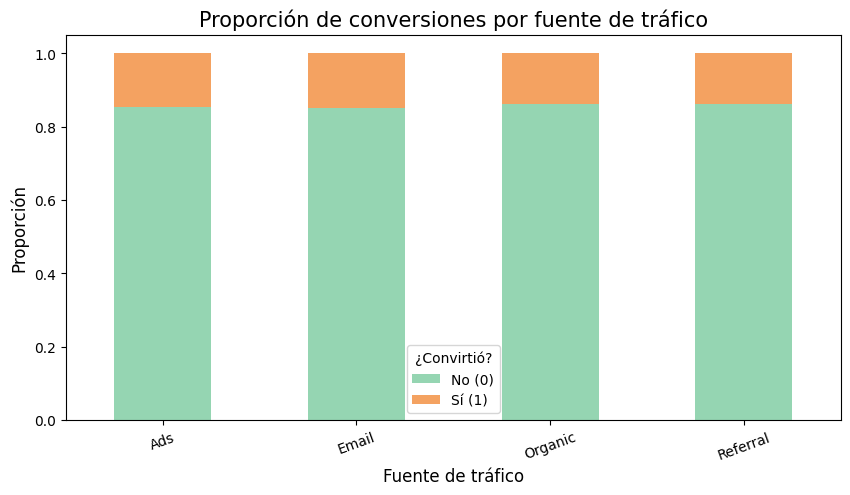

In [54]:
tabla_prop = pd.crosstab(
    df['traffic_source'],
    df['converted'],
    normalize='index'
)

# Gráfico de barras apiladas
tabla_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(10,5),
    color=["#95D5B2", "#F4A261"]
)

# Añadir detalles
plt.title('Proporción de conversiones por fuente de tráfico', fontsize=15)
plt.xlabel('Fuente de tráfico', fontsize=12)
plt.ylabel('Proporción', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.xticks(rotation=20)
plt.show()

✍️ **Comentario**: Las proporciones de conversión varían ligeramente entre las diferentes fuentes de tráfico. Aunque Organic genera el mayor número de conversiones en términos absolutos, Email y Ads presentan una proporción de conversión similar o incluso ligeramente superior. 

a pesar de que visualmente las proporciones se ven similiares, las diferencias se vuelven significativas para el negocio teniendo en cuenta la gran cantidad de usuarios incluidos en el analisis

### Relación entre el tipo de usuario y la conversión

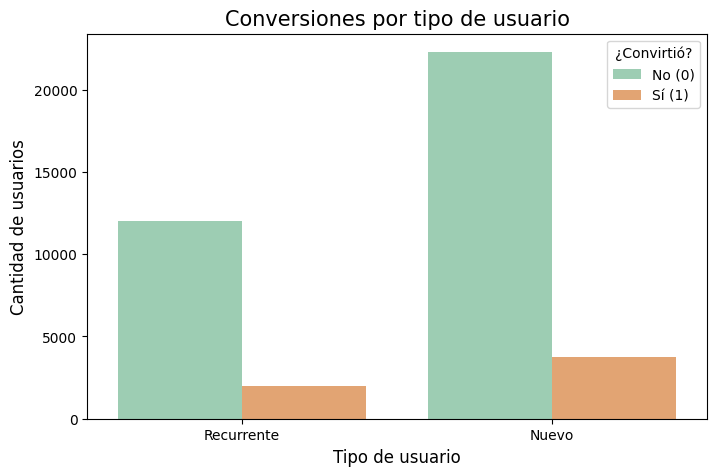

In [55]:
# Gráfico de barras agrupadas
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='user_type',
    hue='converted',
    palette=["#95D5B2", "#F4A261"]
)

# Añadir detalles
plt.title('Conversiones por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()

✍️ **Comentario**: 

Los usuarios nuevos representan un mayor volumen de conversiones que los usuarios recurrentes, debido a que también constituyen la mayor parte de los usuarios analizados. Sin embargo, visualmente las proporciones de usuarios que convierten y no convierten son similares en ambos grupos, lo que coincide con la prueba de chi-cuadrado, la cual no encontró evidencia de una asociación estadísticamente significativa entre el tipo de usuario y la conversión.

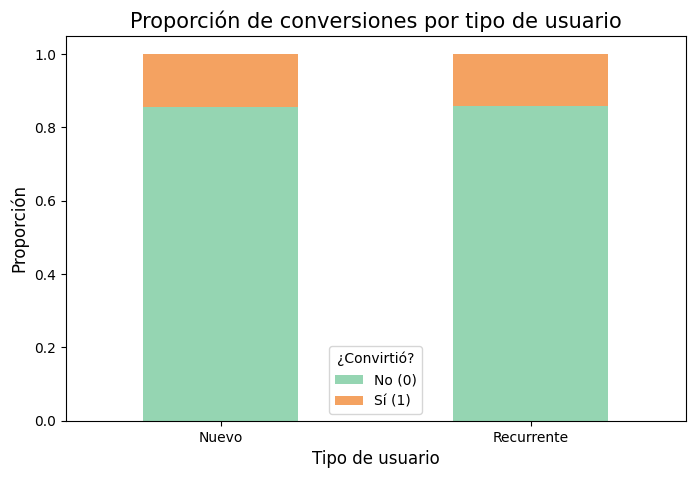

In [56]:
tabla_prop = pd.crosstab(
    df['user_type'],
    df['converted'],
    normalize='index'
)

# Gráfico de barras apiladas
tabla_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5),
    color=["#95D5B2", "#F4A261"]
)

# Añadir detalles
plt.title('Proporción de conversiones por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario', fontsize=12)
plt.ylabel('Proporción', fontsize=12)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.xticks(rotation=0)
plt.show()

✍️ **Comentario**: Las proporciones de usuarios que convierten son muy similares entre usuarios nuevos y recurrentes. Esto coincide con el resultado de la prueba de chi-cuadrado (p = 0.4736), que no encontró evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión.

## 7. Síntesis ejecutiva

Los hallazgos del experimento sustentan recomendaciones sobre la versión de la página, la conversión, el gasto promedio y la segmentación por fuente de tráfico y tipo de usuario.


### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- Se encontraron diferencias estadísticamente significativas en el gasto promedio entre los usuarios que convirtieron en la página A y la página B (prueba t, p < 0.001)
- Los usuarios que convirtieron en la página B registraron un gasto promedio superior al de la página A.
- **Interpretación:** 
La página B no solo logra conversiones, sino que también genera un mayor valor económico por usuario convertido, lo que la convierte en la alternativa más rentable.
<br>

**Tasa de conversión:** 
- Se encontraron diferencias estadísticamente significativas en la tasa de conversión entre la página A y la página B (prueba z, p < 0.001)
- La página B presentó una tasa de conversión superior a la de la página A
- **Interpretación:**
La página B es más efectiva para convertir visitantes en clientes, por lo que representa la mejor opción para maximizar el número de conversiones
---

#### 📊 **Segmentación por fuente de tráfico**
- Se encontró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (prueba de chi-cuadrado, p = 0.0341). Aunque las diferencias en las tasas de conversión son pequeñas,
- **Interpretación:**
 La fuente de tráfico influye en la probabilidad de conversión, por lo que es recomendable monitorear y optimizar la inversión en los canales con mejor desempeño como ads y email, que fueron las que numericamente tienen mejores tasas de conversion u n 1% mas que las otras dos fuentes
 

#### 📊 **Segmentación por tipo de usuario**
- No se encontró una asociación estadísticamente significativa entre el tipo de usuario (nuevo o recurrente) y la conversión (prueba de chi-cuadrado, p = 0.4736). Las tasas de conversión fueron similares en ambos grupos.
- **Interpretación:**
El tipo de usuario no parece influir en la probabilidad de conversión, por lo que no se justifica una estrategia diferenciada basada únicamente en esta variable.

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:** 
- Implementar la página B como versión principal, ya que presenta una mayor tasa de conversión y un mayor gasto promedio por usuario convertido.
- Optimizar la inversión en los canales de tráfico con mejor desempeño, monitoreando tanto el volumen de conversiones como la tasa de conversión para maximizar el retorno de las campañas.
- No segmentar estrategias únicamente por tipo de usuario (nuevo o recurrente), ya que no se encontraron diferencias significativas en la probabilidad de conversión.